# 3. Preliminary checks of the cleaned MrP input and survey targets (7-day windows)




In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from belief_recodes_7d import n_categories, recode_value

DATA_DIR = "../../Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data"
MRP_PKL = f"{DATA_DIR}/feature_extraction/preprocessed_cleaned_all_result_7d.pkl"
TARGET_DIR = f"{DATA_DIR}/target_df_7d"
FEATURES_JSON = f"{DATA_DIR}/updated_belief_features.json"

# chart colors: LLM in the one accent hue, surveys in gray; survey identity is carried by marker shape
LLM = "#2a78d6"
SURVEY = "#7c7b75"
MUTED = "#9a9992"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e4e3df"
SURFACE = "#fcfcfb"
SURVEY_MARKER = {"ANES": "o", "CCES": "s", "GSS": "D"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 9, "text.color": INK, "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 9, "axes.titlecolor": INK,
    "xtick.major.size": 0, "ytick.major.size": 0,
})
pd.set_option("display.max_rows", 100, "display.max_columns", 30, "display.width", 200, "display.max_colwidth", 60)

TOPICS = {
    "LETIN1A": "Number of immigrants", "IMMCRIME1": "Immigrants increase crime", "IMMJOBS1": "Immigrants take jobs",
    "IMMFATE": "Undocumented immigrants: what to do", "DIVLAW": "Divorce easier / harder", "ABANY": "Abortion for any reason",
    "MARSAME": "Same-sex marriage", "FEPOLV": "Men better suited to politics", "FEFAM": "Man works, woman runs home",
    "V242353x": "Spending on health insurance help", "V242357x": "Vaccine benefits vs risks", "COURTS": "Courts too harsh / lenient",
    "CC24_443d": "State law-enforcement spending", "GRASS": "Legalize marijuana", "GUNLAW": "Police permit to buy a gun",
    "CC24_440a": "White people have advantages", "AFFRMACT": "Preferential hiring of Black people",
    "CC24_444a": "Ban gender surgery for minors", "SATDEMOC": "Satisfaction with democracy", "BIASNEWS": "Media coverage is biased",
    "SMNEWS": "Reliability of social-media news", "CC24_326d": "Increase fossil-fuel production",
    "TEMPGEN1": "Danger of climate warming", "V241409x": "Side with Israel / Palestine", "V241403x": "Military aid to Israel",
    "V241400x": "Weapons for Ukraine", "CONLABORY": "Confidence in labor unions", "V241294x": "National economy, past year",
    "V241137x": "Biden approval", "V241129x": "Congress approval", "V241133x": "Supreme Court approval",
    "V241229": "Trust the federal government", "WRKWAYUP": "Work way up without favors",
    "V242301": "Slavery makes moving up hard", "V241608": "Women seek power over men", "V242331x": "Ban assault-style rifles",
    "V242328x": "Background checks, private sales", "V241395x": "Border wall with Mexico", "CAPPUN": "Death penalty",
    "EQWLTH": "Government reduce income gap",
}

## 1. Load

In [2]:
with open(FEATURES_JSON, "r", encoding="utf-8") as f:
    belief_features = json.load(f)["beliefs"]
ids = [f["id"] for f in belief_features]
assert set(TOPICS) == set(ids)

def recoded_labels(feature):
    # option text per recoded value; options merged by a recode are joined with " / "
    labels = {}
    for position, text in enumerate(feature["options"], start=1):
        labels.setdefault(recode_value(feature["id"], position), []).append(text)
    return {value: " / ".join(texts) for value, texts in sorted(labels.items())}

option_labels = {f["id"]: recoded_labels(f) for f in belief_features}
K = {f["id"]: n_categories(f["id"], len(f["options"])) for f in belief_features}

# LLM side: rows MrP can use, i.e. all predictors present
PREDICTORS = [f"Demo_{name}_idx" for name in ["sex", "age", "ethnicity", "income", "education", "past_vote"]] + ["state_cleaned_idx"]
mrp = pd.read_pickle(MRP_PKL)
llm = mrp.dropna(subset=PREDICTORS).copy()
llm["window"] = pd.to_datetime(llm["time_window_start"], utc=True).dt.tz_convert(None)
windows = pd.DatetimeIndex(sorted(pd.to_datetime(mrp["time_window_start"], utc=True).dt.tz_convert(None).unique()))
assert len(windows) == 52

# survey side
target_map = pd.read_csv(f"{TARGET_DIR}/target_map_7d.csv")
for col in ["map", "llm_map"]:
    target_map[col] = target_map[col].map(lambda s: json.loads(s) if isinstance(s, str) else None)
target_map["llm_map"] = target_map["llm_map"].map(lambda m: {int(k): v for k, v in m.items()} if m else None)
survey_name = {"ANES2024": "ANES", "CCES2024": "CCES", "gss": "GSS"}
targets = pd.concat([pd.read_csv(f"{TARGET_DIR}/basic_{s}_target_df_7d.csv", low_memory=False) for s in ["anes", "cces", "gss"]],
                    ignore_index=True)
targets["survey"] = targets["benchmark"].map(survey_name)
targets["id"] = targets["question_id"].str.removeprefix("Belief_").str.removesuffix("_Symbol")
targets["window"] = pd.to_datetime(targets["time_window_bin"].str[1:11])

print(f"MrP input: {len(mrp):,} rows -> {len(llm):,} with all predictors, from {llm['id'].nunique()} users")
print(f"Targets: {len(targets):,} answers, {len(target_map)} targets "
      f"({target_map['wording_source'].sum()} wording source, {target_map['confidence_low'].sum()} low confidence)")

MrP input: 46,065 rows -> 17,589 with all predictors, from 889 users
Targets: 1,110,700 answers, 68 targets (40 wording source, 7 low confidence)


## 2. MrP input coverage

Usable user-windows per week, and how many each user contributes.

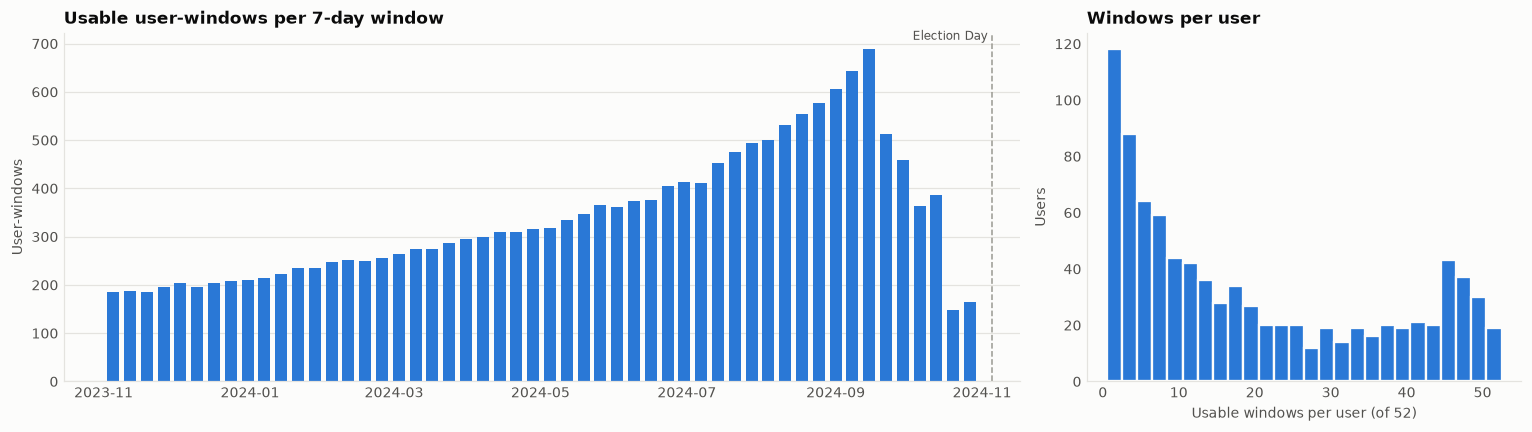

Per week: median 310, min 149 (2024-10-20), max 688 (2024-09-15)
Per user: median 14, 56 users with a single window


In [3]:
per_week = llm.groupby("window").size().reindex(windows, fill_value=0)
per_user = llm.groupby("id").size()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.bar(per_week.index, per_week.values, width=5, color=LLM)
ax1.axvline(pd.Timestamp("2024-11-05"), color=MUTED, lw=1, ls="--")
ax1.text(pd.Timestamp("2024-11-05"), per_week.max() * 1.02, "Election Day ", ha="right", va="bottom", color=INK_SECONDARY, fontsize=8)
ax1.set_ylabel("User-windows")
ax1.grid(axis="y", color=GRID, lw=0.8)
ax1.set_axisbelow(True)
ax1.set_title("Usable user-windows per 7-day window", fontsize=11, fontweight="bold")

ax2.hist(per_user, bins=np.arange(0.5, 53.5, 2), color=LLM, edgecolor=SURFACE, lw=1.5)
ax2.set_xlabel("Usable windows per user (of 52)")
ax2.set_ylabel("Users")
ax2.set_title("Windows per user", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Per week: median {per_week.median():.0f}, min {per_week.min()} ({per_week.idxmin().date()}), max {per_week.max()} ({per_week.idxmax().date()})")
print(f"Per user: median {per_user.median():.0f}, {(per_user == 1).sum()} users with a single window")

## 3. Sample composition: LLM vs surveys

LLM demographics mapped to the coarse target groups. Each dot is the share of that group in one source. Surveys are unweighted respondents; the LLM side is user-windows.

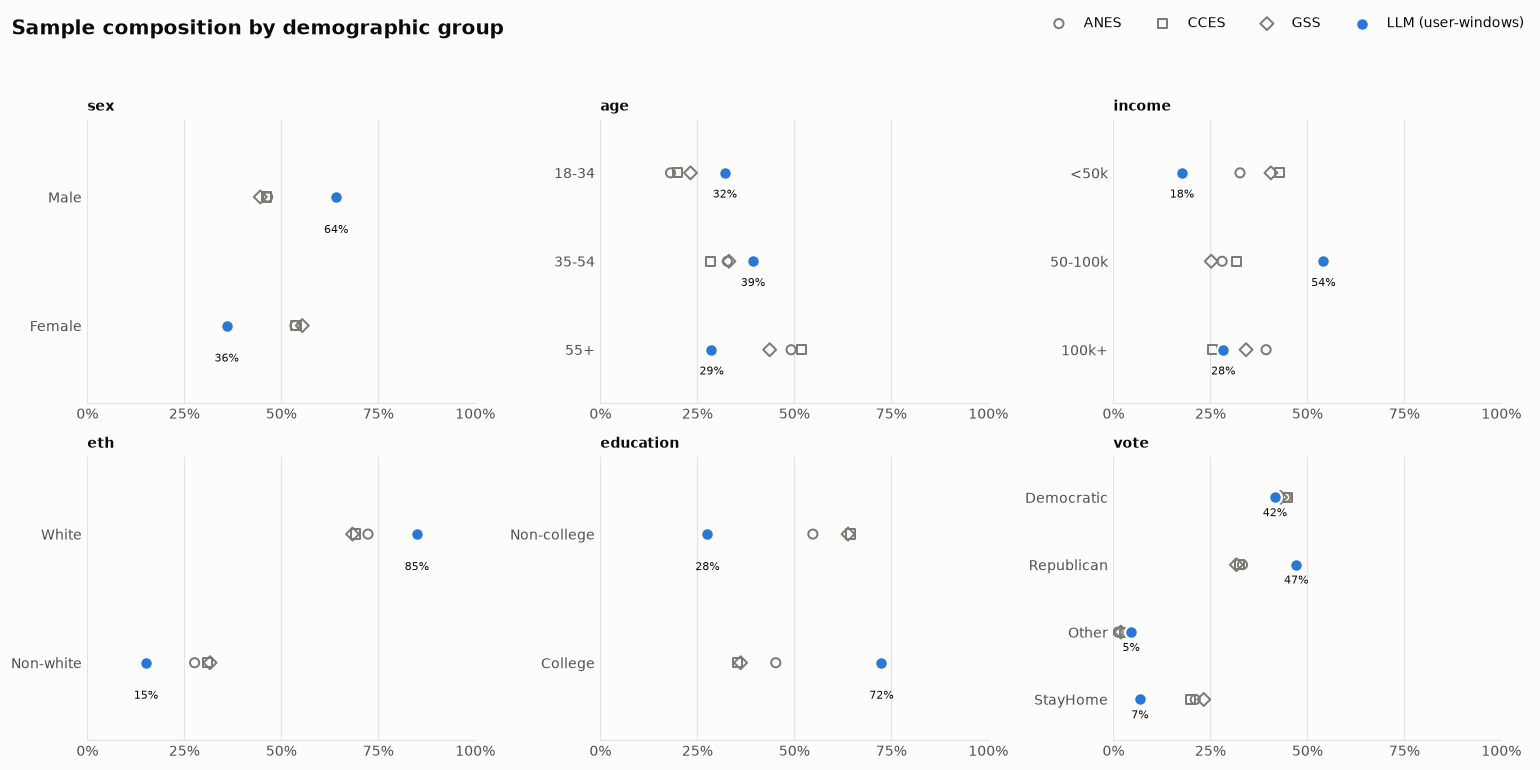

LLM   ANES   CCES    GSS
sex       Male         0.641  0.465  0.462  0.446
          Female       0.359  0.535  0.538  0.554
age       35-54        0.393  0.327  0.283  0.331
          18-34        0.321  0.181  0.198  0.232
          55+          0.286  0.492  0.519  0.436
income    50-100k      0.541  0.280  0.317  0.252
          100k+        0.283  0.394  0.255  0.342
          <50k         0.176  0.326  0.428  0.406
eth       White        0.849  0.724  0.691  0.684
          Non-white    0.151  0.276  0.309  0.316
education College      0.724  0.452  0.354  0.361
          Non-college  0.276  0.548  0.646  0.639
vote      Republican   0.471  0.333  0.324  0.317
          Democratic   0.416  0.444  0.449  0.431
          StayHome     0.068  0.211  0.199  0.233
          Other        0.045  0.012  0.028  0.019

In [4]:
COARSE = {
    "sex": ("Demo_sex_idx", {1: "Male", 2: "Female"}),
    "age": ("Demo_age_idx", {1: "18-34", 2: "18-34", 3: "35-54", 4: "35-54", 5: "55+", 6: "55+"}),
    "income": ("Demo_income_idx", {1: "<50k", 2: "<50k", 3: "50-100k", 4: "50-100k", 5: "100k+"}),
    "eth": ("Demo_ethnicity_idx", {1: "White", 2: "Non-white", 3: "Non-white", 4: "Non-white", 5: "Non-white", 6: "Non-white"}),
    "education": ("Demo_education_idx", {1: "Non-college", 2: "College"}),
    "vote": ("Demo_past_vote_idx", {1: "StayHome", 2: "Republican", 3: "Democratic", 4: "Other", 5: "Other", 6: "Other"}),
}
ORDER = {
    "sex": ["Male", "Female"], "age": ["18-34", "35-54", "55+"], "income": ["<50k", "50-100k", "100k+"],
    "eth": ["White", "Non-white"], "education": ["Non-college", "College"],
    "vote": ["Democratic", "Republican", "Other", "StayHome"],
}
for name, (col, mapping) in COARSE.items():
    llm[name] = llm[col].map(mapping)

respondents = targets.drop_duplicates(["survey", "respondent_id"])
composition = {"LLM": {name: llm[name].value_counts(normalize=True) for name in COARSE}}
for survey, df in respondents.groupby("survey"):
    composition[survey] = {name: df[name].value_counts(normalize=True) for name in COARSE}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, name in zip(axes.flat, COARSE):
    y = np.arange(len(ORDER[name]))
    for survey in ["ANES", "CCES", "GSS"]:
        shares = composition[survey][name].reindex(ORDER[name])
        ax.scatter(shares, y, s=36, marker=SURVEY_MARKER[survey], facecolor="none", edgecolor=SURVEY, lw=1.3, zorder=2, label=survey)
    shares = composition["LLM"][name].reindex(ORDER[name])
    ax.scatter(shares, y, s=70, color=LLM, edgecolor=SURFACE, lw=1.5, zorder=3, label="LLM (user-windows)")
    for yi, s in zip(y, shares):
        ax.text(s, yi + 0.28, f"{s:.0%}", ha="center", fontsize=7.5, color=INK)
    ax.set_yticks(y, ORDER[name])
    ax.set_ylim(-0.6, len(y) - 0.4)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"])
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_title(name, fontweight="bold")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=4, frameon=False, bbox_to_anchor=(1, 1.0))
fig.suptitle("Sample composition by demographic group", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

pd.concat({src: pd.concat(groups) for src, groups in composition.items()}, axis=1).round(3)

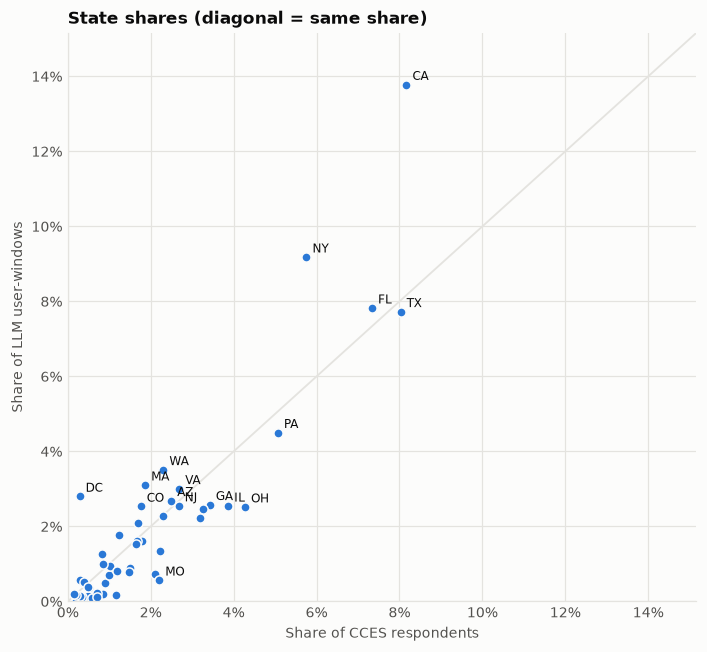

51 states with LLM rows; correlation of shares 0.90


In [5]:
# state shares: LLM user-windows vs CCES respondents (the only survey with a large state sample)
llm_state = llm["state_cleaned"].value_counts(normalize=True)
cces_state = respondents.loc[respondents["survey"] == "CCES", "state_abbr"].value_counts(normalize=True)
states = pd.DataFrame({"llm": llm_state, "cces": cces_state}).fillna(0)

fig, ax = plt.subplots(figsize=(6.5, 6))
top = states["llm"].max() * 1.1
ax.plot([0, top], [0, top], color=GRID, lw=1.2, zorder=1)
ax.scatter(states["cces"], states["llm"], s=36, color=LLM, edgecolor=SURFACE, lw=1, zorder=2)
for abbr, row in states.iterrows():
    if row["llm"] > 0.025 or abs(row["llm"] - row["cces"]) > 0.015:
        ax.annotate(abbr, (row["cces"], row["llm"]), xytext=(4, 3), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlim(0, top)
ax.set_ylim(0, top)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("Share of CCES respondents")
ax.set_ylabel("Share of LLM user-windows")
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.set_title("State shares (diagonal = same share)", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()
print(f"{(states['llm'] > 0).sum()} states with LLM rows; correlation of shares {states['llm'].corr(states['cces']):.2f}")

## 4. Beliefs: LLM vs the wording-source survey

Share choosing each (recoded) option, LLM user-windows vs the respondents of the survey the wording came from. Same options in the same order on both sides, so a mirrored pattern would mean a reversed scale.

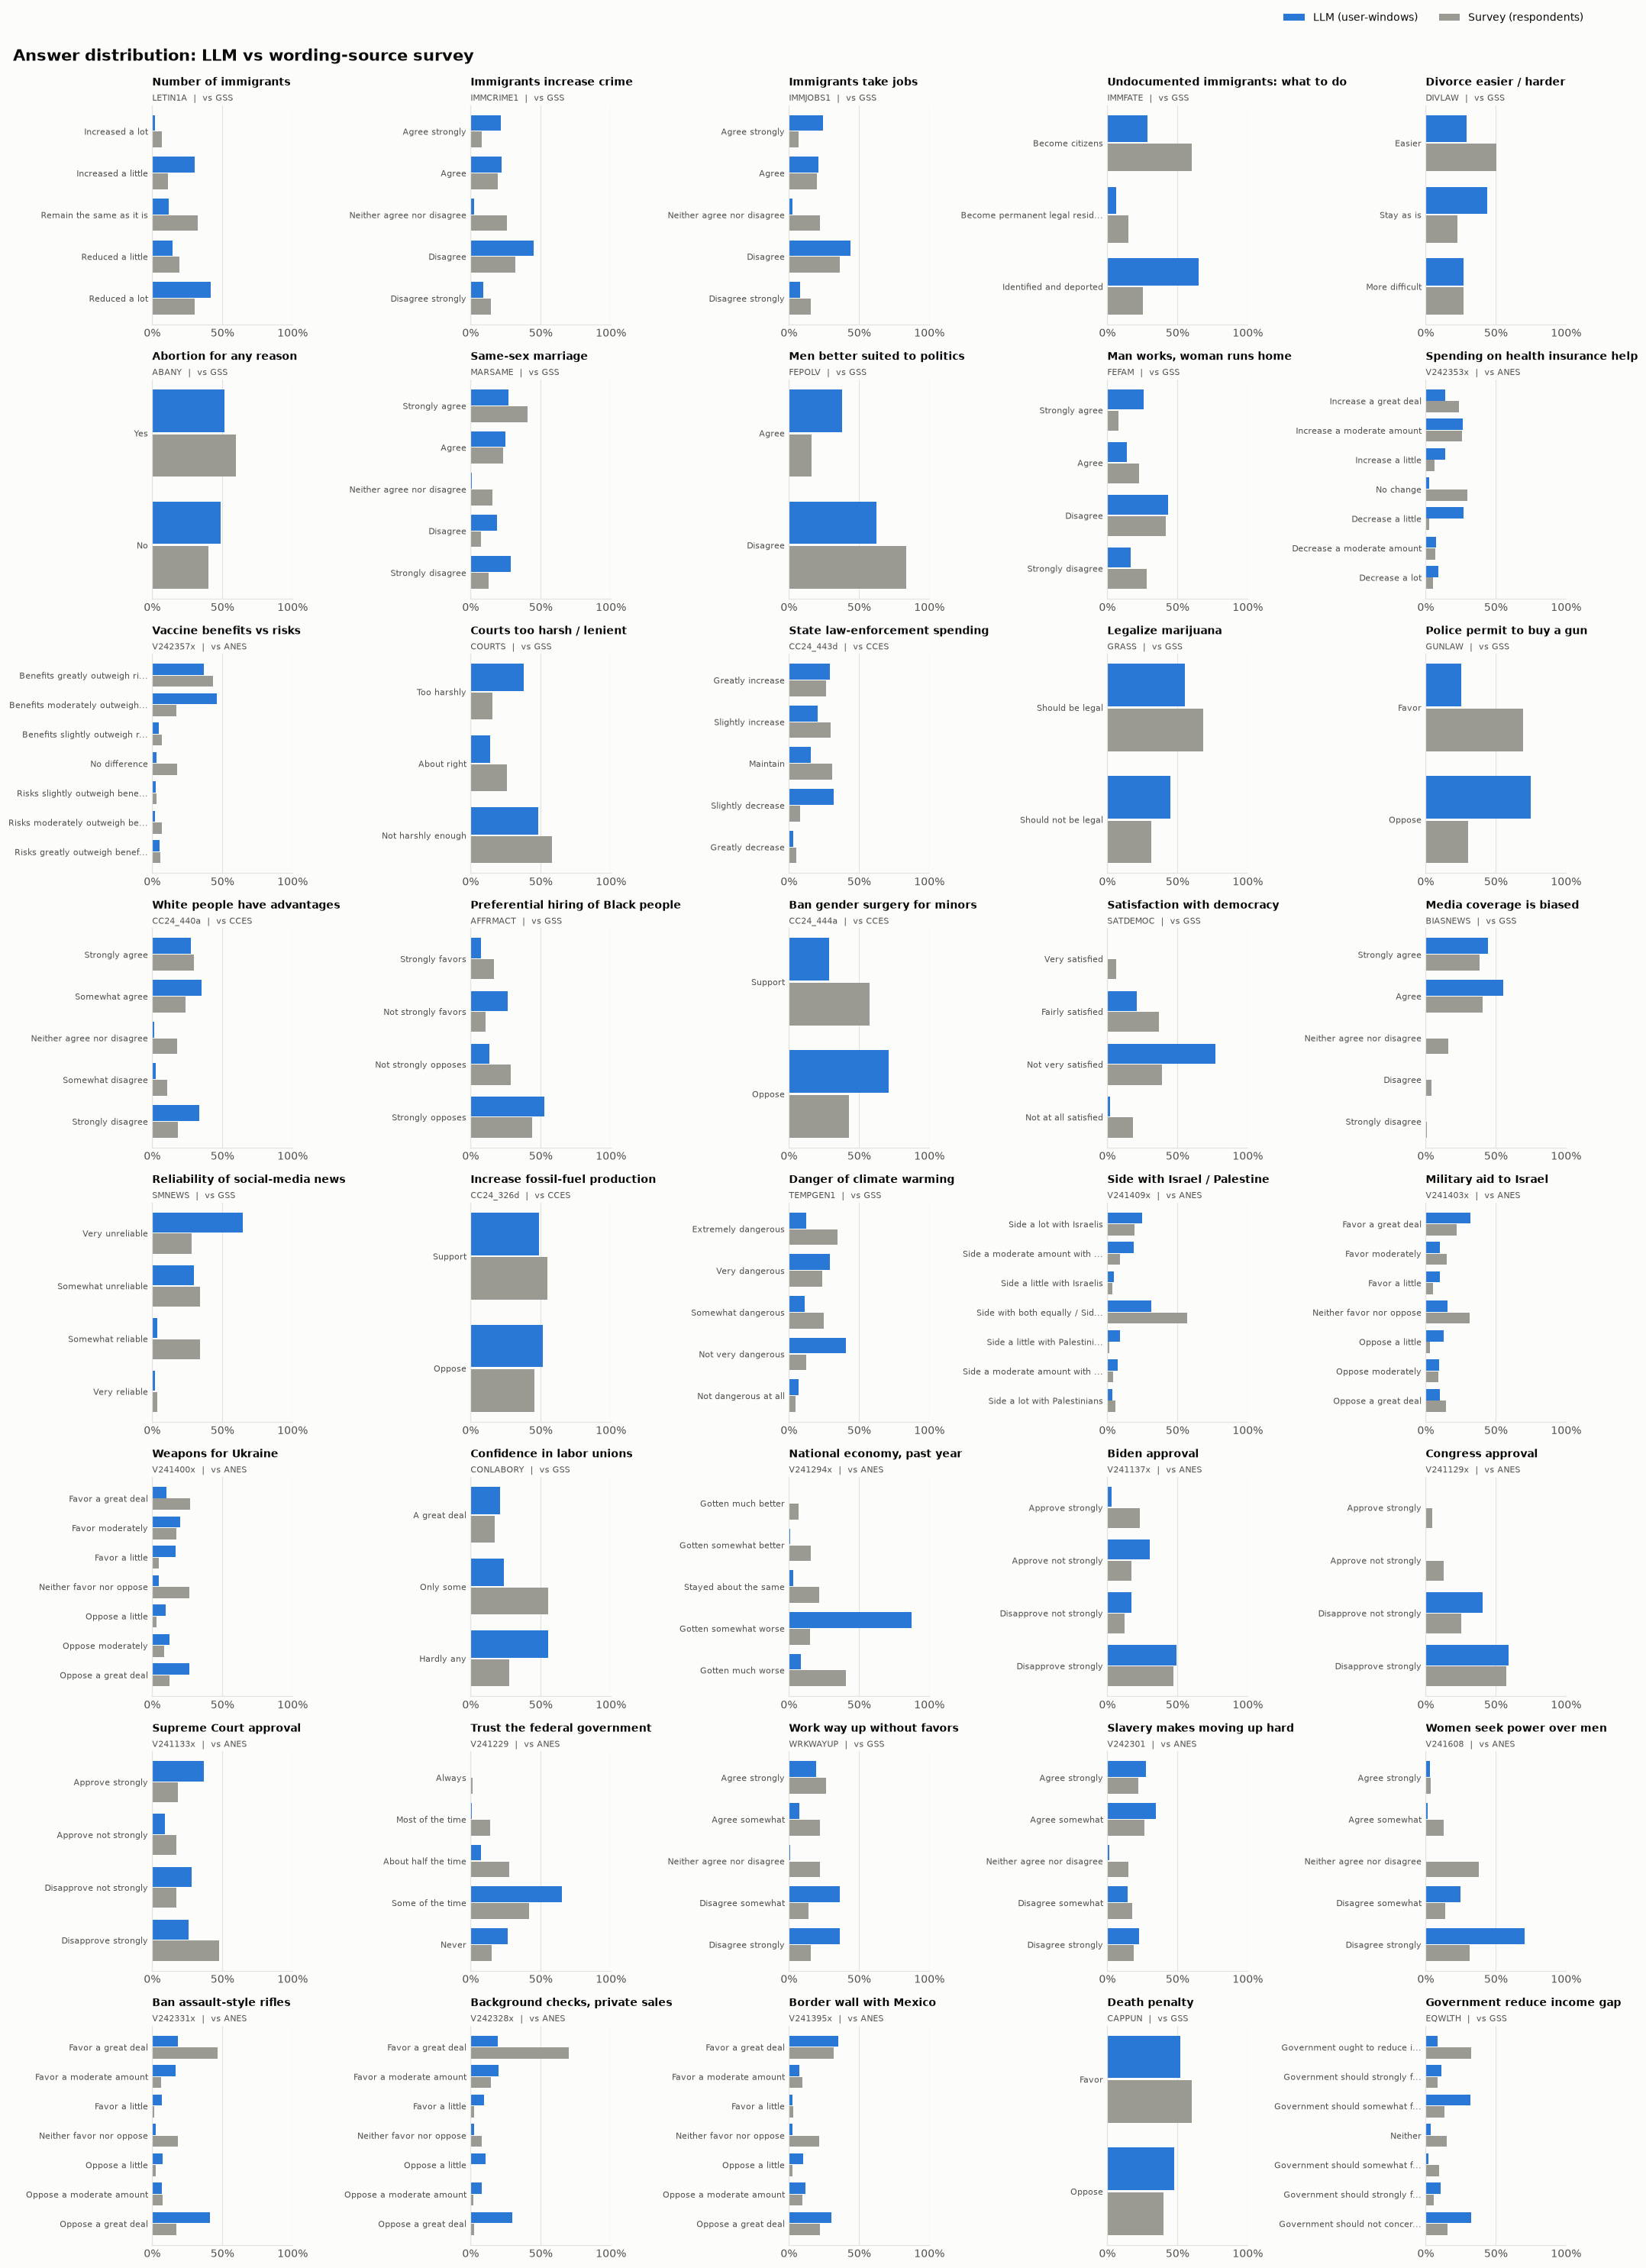

In [6]:
source = target_map[target_map["wording_source"]].set_index("id")
wording_targets = targets[targets["wording_source"]]

def shares(values, k):
    return values.value_counts(normalize=True).reindex(range(1, k + 1), fill_value=0)

n_cols, n_rows = 5, 8
fig, axes = plt.subplots(n_rows, n_cols, figsize=(19, 27), sharex=True)
for ax, key in zip(axes.flat, ids):
    k = K[key]
    llm_shares = shares(llm[f"Belief_{key}_Symbol_num"].dropna(), k)
    survey_shares = shares(wording_targets.loc[wording_targets["id"] == key, "belief_value"], k)
    pos = np.arange(k)
    ax.barh(pos - 0.2, llm_shares.values, height=0.38, color=LLM, label="LLM (user-windows)")
    ax.barh(pos + 0.2, survey_shares.values, height=0.38, color=MUTED, label="Survey (respondents)")
    labels = [t if len(t) <= 30 else t[:28] + "..." for t in option_labels[key].values()]
    ax.set_yticks(pos, labels, fontsize=7.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.5, 1], ["0%", "50%", "100%"])
    ax.tick_params(axis="x", labelbottom=True)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_title(f"{TOPICS[key]}\n", fontweight="bold")
    ax.text(0, 1.02, f"{key}  |  vs {source.loc[key, 'survey']}", transform=ax.transAxes, fontsize=7.5, color=INK_SECONDARY)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False, bbox_to_anchor=(1, 1.0))
fig.suptitle("Answer distribution: LLM vs wording-source survey", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.985))
plt.show()

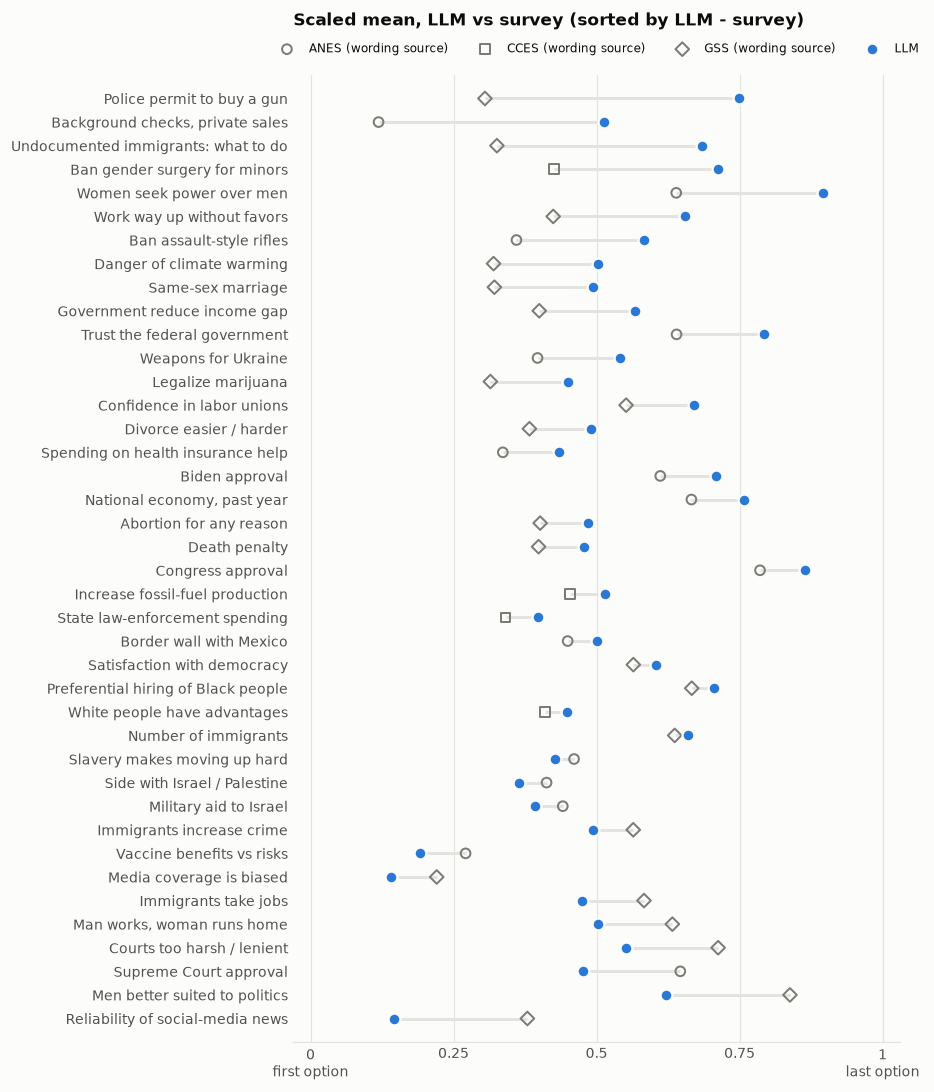

Mean absolute difference 0.140; correlation of the 40 scaled means 0.54


,id,topic,survey,K,llm_scaled,survey_scaled,llm_n,survey_n,diff
14,GUNLAW,Police permit to buy a gun,GSS,2,0.749,0.305,17587,2191,0.444
36,V242328x,"Background checks, private sales",ANES,7,0.513,0.119,17587,4718,0.394
3,IMMFATE,Undocumented immigrants: what to do,GSS,3,0.684,0.326,17587,2170,0.359
17,CC24_444a,Ban gender surgery for minors,CCES,2,0.713,0.425,17587,49420,0.287
34,V241608,Women seek power over men,ANES,5,0.896,0.639,17587,5148,0.257
20,SMNEWS,Reliability of social-media news,GSS,4,0.145,0.379,17587,1436,-0.234
32,WRKWAYUP,Work way up without favors,GSS,5,0.655,0.424,17587,2130,0.231
35,V242331x,Ban assault-style rifles,ANES,7,0.583,0.360,17587,4706,0.223
7,FEPOLV,Men better suited to politics,GSS,2,0.622,0.838,17587,500,-0.216
22,TEMPGEN1,Danger of climate warming,GSS,5,0.502,0.320,17587,515,0.182


In [7]:
# one number per question: scaled mean on each side
rows = []
for key in ids:
    k = K[key]
    llm_values = llm[f"Belief_{key}_Symbol_num"].dropna().astype(float)
    survey_values = wording_targets.loc[wording_targets["id"] == key, "belief_value"]
    rows.append({"id": key, "topic": TOPICS[key], "survey": source.loc[key, "survey"], "K": k,
                 "llm_scaled": (llm_values.mean() - 1) / (k - 1), "survey_scaled": (survey_values.mean() - 1) / (k - 1),
                 "llm_n": len(llm_values), "survey_n": len(survey_values)})
compare = pd.DataFrame(rows)
compare["diff"] = compare["llm_scaled"] - compare["survey_scaled"]
order = compare.sort_values("diff").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 10))
y = np.arange(len(order))
ax.hlines(y, order["survey_scaled"], order["llm_scaled"], color=GRID, lw=2, zorder=1)
for survey, part in order.groupby("survey"):
    ax.scatter(part["survey_scaled"], part.index, s=40, marker=SURVEY_MARKER[survey], facecolor="none",
               edgecolor=SURVEY, lw=1.3, zorder=2, label=f"{survey} (wording source)")
ax.scatter(order["llm_scaled"], y, s=60, color=LLM, edgecolor=SURFACE, lw=1.5, zorder=3, label="LLM")
ax.set_yticks(y, order["topic"])
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-1, len(order))
ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0\nfirst option", "0.25", "0.5", "0.75", "1\nlast option"])
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.045), ncol=4, frameon=False, fontsize=8)
ax.set_title("Scaled mean, LLM vs survey (sorted by LLM - survey)\n\n", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Mean absolute difference {compare['diff'].abs().mean():.3f}; correlation of the 40 scaled means {compare['llm_scaled'].corr(compare['survey_scaled']):.2f}")
compare.sort_values("diff", key=abs, ascending=False).round(3)

## 5. Survey targets per 7-day window

Respondents with at least one answer, per window. ANES and CCES are binned by the pre-election interview date, also for post-election items (`wave` = post) -- see the open question in the project notes.

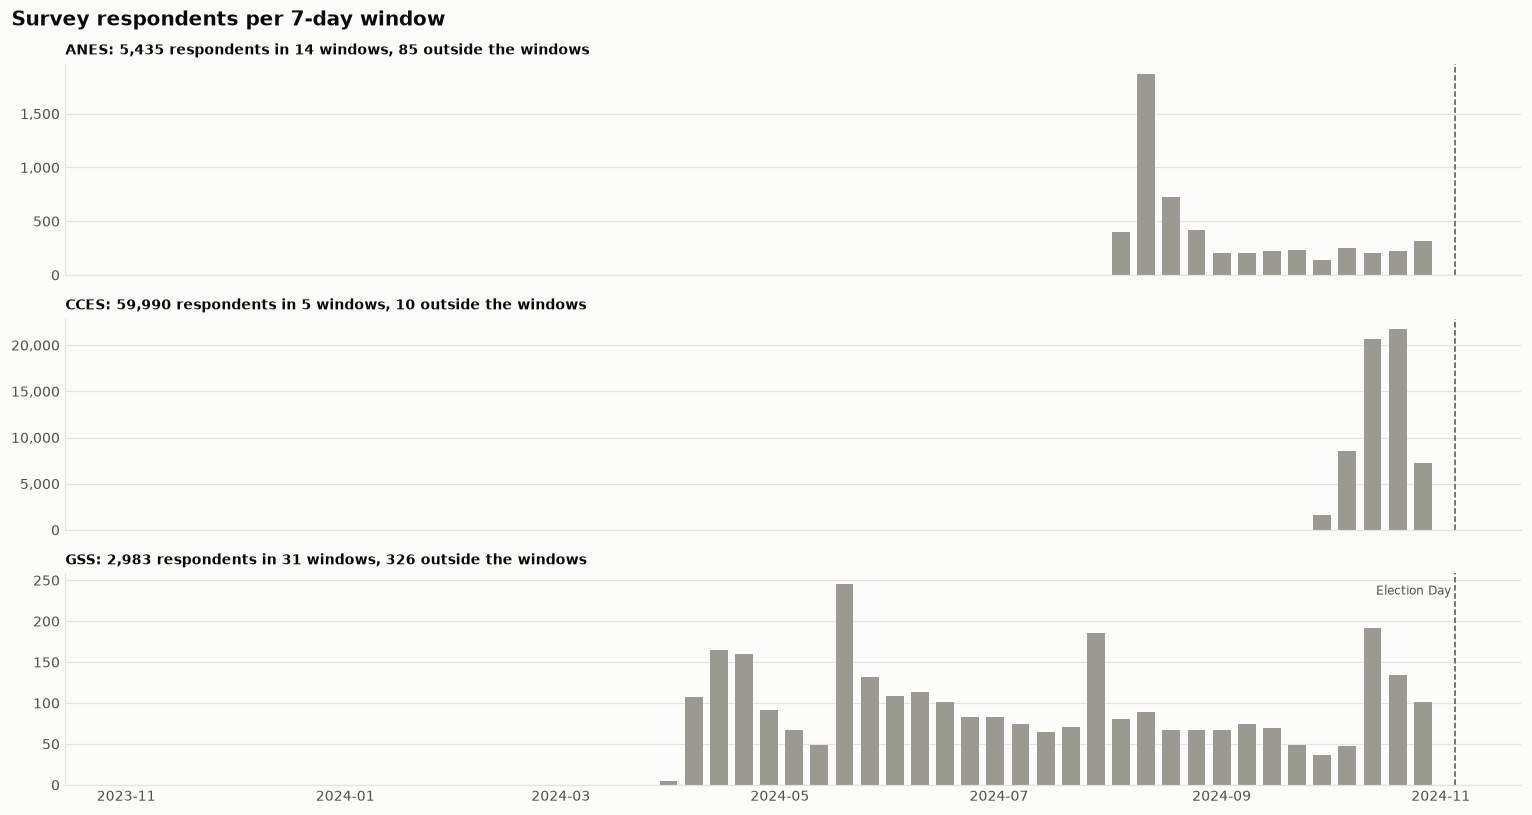

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
for ax, survey in zip(axes, ["ANES", "CCES", "GSS"]):
    df = respondents[respondents["survey"] == survey]
    counts = df.groupby("window").size().reindex(windows, fill_value=0)
    ax.bar(counts.index, counts.values, width=5, color=MUTED)
    ax.axvline(pd.Timestamp("2024-11-05"), color=INK_SECONDARY, lw=1, ls="--")
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    no_window = df["window"].isna().sum()
    ax.set_title(f"{survey}: {counts.sum():,} respondents in {(counts > 0).sum()} windows, {no_window:,} outside the windows",
                 fontweight="bold")
axes[-1].text(pd.Timestamp("2024-11-05"), axes[-1].get_ylim()[1] * 0.9, "Election Day ", ha="right", color=INK_SECONDARY, fontsize=8)
fig.suptitle("Survey respondents per 7-day window", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## 6. Other-survey targets vs the wording-source target

For the 21 other-survey targets on our full scale: scaled mean next to the wording-source survey's. A large gap points at a scale or merge problem, or a real wording effect. Hollow = `confidence_low`. The 7 targets on a collapsed scale (binary, or the 4-point trust) are in the table below, with the LLM answers collapsed the same way.

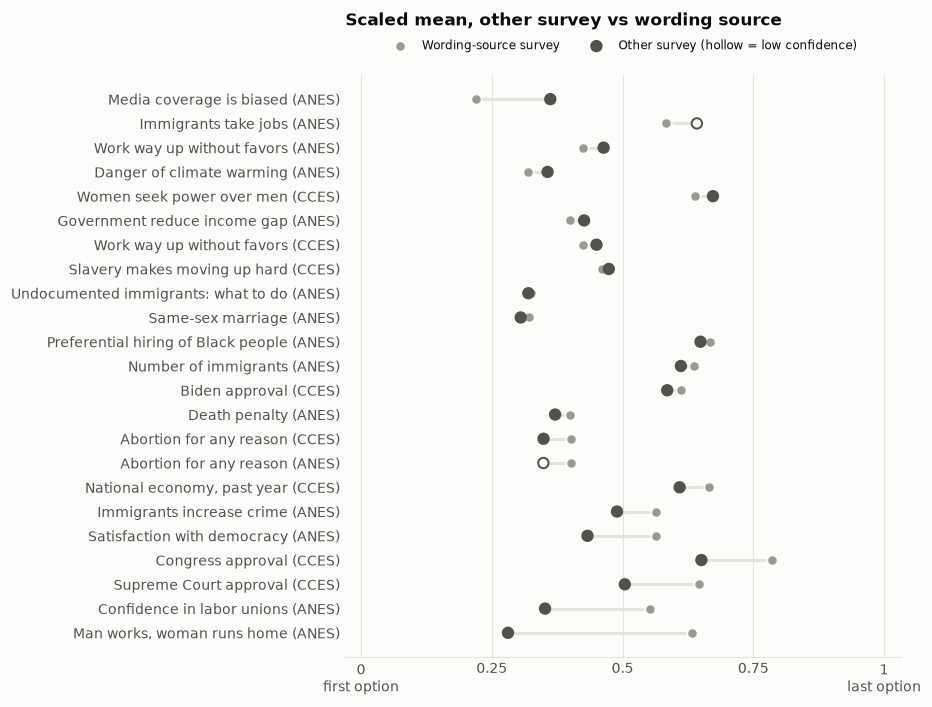

,id,topic,other_survey,var,low,source_scaled,other_scaled,n,note,diff
0,FEFAM,"Man works, woman runs home",ANES,V242279x,False,0.632,0.281,1514,better / worse for the family; 4 'makes no difference' (...,-0.352
1,CONLABORY,Confidence in labor unions,ANES,V242140,False,0.552,0.352,4850,"0-100 thermometer cut into equal thirds, reversed",-0.200
2,V241133x,Supreme Court approval,CCES,CC24_312d,False,0.646,0.504,55126,NaN,-0.142
3,V241129x,Congress approval,CCES,CC24_312c,False,0.786,0.651,54121,NaN,-0.135
4,SATDEMOC,Satisfaction with democracy,ANES,V242439,False,0.564,0.433,4676,NaN,-0.131
5,IMMCRIME1,Immigrants increase crime,ANES,V242453,False,0.564,0.489,4687,NaN,-0.075
6,V241294x,"National economy, past year",CCES,CC24_301,False,0.666,0.609,58452,NaN,-0.057
7,ABANY,Abortion for any reason,ANES,V241248,True,0.401,0.349,4266,7-point always permitted .. never permitted; 4 and 99 'h...,-0.053
8,ABANY,Abortion for any reason,CCES,CC24_324a,False,0.401,0.349,59971,support 'always allow ... as a matter of choice' = yes,-0.053
9,CAPPUN,Death penalty,ANES,V241308x,False,0.399,0.371,5180,favor / oppose strongly + not strongly merged,-0.028


In [9]:
others = target_map[~target_map["wording_source"]]
same_scale = others[others["llm_map"].isna()]

rows = []
for _, t in same_scale.iterrows():
    k = K[t["id"]]
    other = targets.loc[(targets["id"] == t["id"]) & (targets["survey"] == t["survey"]), "belief_value"]
    rows.append({"id": t["id"], "topic": TOPICS[t["id"]], "other_survey": t["survey"], "var": t["var"],
                 "low": t["confidence_low"], "source_scaled": compare.set_index("id").loc[t["id"], "survey_scaled"],
                 "other_scaled": (other.mean() - 1) / (k - 1), "n": len(other), "note": t["note"]})
cross = pd.DataFrame(rows)
cross["diff"] = cross["other_scaled"] - cross["source_scaled"]
cross = cross.sort_values("diff").reset_index(drop=True)
cross["label"] = cross["topic"] + " (" + cross["other_survey"] + ")"

fig, ax = plt.subplots(figsize=(8.5, 6.5))
y = np.arange(len(cross))
ax.hlines(y, cross["source_scaled"], cross["other_scaled"], color=GRID, lw=2, zorder=1)
ax.scatter(cross["source_scaled"], y, s=46, color=MUTED, edgecolor=SURFACE, lw=1.2, zorder=2, label="Wording-source survey")
ax.scatter(cross["other_scaled"], y, s=46, facecolor=np.where(cross["low"], SURFACE, INK_SECONDARY),
           edgecolor=INK_SECONDARY, lw=1.3, zorder=3, label="Other survey (hollow = low confidence)")
ax.set_yticks(y, cross["label"])
ax.set_xlim(-0.03, 1.03)
ax.set_ylim(-1, len(cross))
ax.set_xticks([0, 0.25, 0.5, 0.75, 1], ["0\nfirst option", "0.25", "0.5", "0.75", "1\nlast option"])
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.spines["left"].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False, fontsize=8)
ax.set_title("Scaled mean, other survey vs wording source\n\n", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()
cross.drop(columns="label").round(3)

In [10]:
# collapsed-scale targets: share in each target category, survey vs LLM collapsed with llm_map
rows = []
for _, t in others[others["llm_map"].notna()].iterrows():
    target_values = targets.loc[(targets["id"] == t["id"]) & (targets["survey"] == t["survey"]), "belief_value"]
    llm_values = llm[f"Belief_{t['id']}_Symbol_num"].dropna().astype(int).map(t["llm_map"]).dropna()
    k = len(set(t["llm_map"].values()))
    rows.append({"id": t["id"], "topic": TOPICS[t["id"]], "survey": t["survey"], "var": t["var"], "K": k,
                 "survey_shares": " / ".join(f"{s:.2f}" for s in shares(target_values, k)),
                 "llm_shares": " / ".join(f"{s:.2f}" for s in shares(llm_values, k)),
                 "llm_kept": len(llm_values) / llm[f"Belief_{t['id']}_Symbol_num"].notna().sum(), "note": t["note"]})
pd.DataFrame(rows).round(3)

,id,topic,survey,var,K,survey_shares,llm_shares,llm_kept,note
0,V241229,Trust the federal government,CCES,CC24_423,4,0.05 / 0.33 / 0.47 / 0.15,0.00 / 0.01 / 0.73 / 0.26,1.000,how much trust (8 = none at all); our 'about half' and '...
1,MARSAME,Same-sex marriage,CCES,CC24_340c,2,0.69 / 0.31,0.52 / 0.48,0.992,bill recognising same-sex and interracial marriages; our...
2,V242331x,Ban assault-style rifles,CCES,CC24_321a,2,0.64 / 0.36,0.43 / 0.57,0.973,binary support / oppose; our neutral dropped
3,V242328x,"Background checks, private sales",CCES,CC24_321c,2,0.93 / 0.07,0.50 / 0.50,0.978,binary support / oppose; our neutral dropped
4,V241395x,Border wall with Mexico,CCES,CC24_323c,2,0.49 / 0.51,0.47 / 0.53,0.977,binary support / oppose; our neutral dropped
